# 01 — Exploratory Data Analysis: Telco Customer Churn

**Goal:** understand who churns and why *before* modeling, check data quality, and find
signals worth turning into features.

Dataset: IBM Telco Customer Churn — one row per customer, target column `Churn` (Yes/No).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Make `src` importable when the notebook runs from notebooks/
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import FIGURES_DIR, RANDOM_STATE
from src.data import load_raw_data

sns.set_theme(style="whitegrid", palette="deep")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_STATE)

def save(fig, name: str) -> None:
    """Save a figure to reports/figures so the README and report can use it."""
    fig.savefig(FIGURES_DIR / name, dpi=120, bbox_inches="tight")

## 1. First look: shape, types, sample rows

In [2]:
df = load_raw_data()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

7,043 rows x 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

`TotalCharges` is stored as **object (text)** although it should be numeric — a red flag.
`SeniorCitizen` is already 0/1 while every other yes/no column is text.

## 2. Missing values

In [4]:
print("Standard NaN check:")
print(df.isna().sum().sum(), "missing values")

# Pandas sees no NaN, but blank strings hide inside TotalCharges.
blank_total = df["TotalCharges"].str.strip() == ""
print(f"\nBlank TotalCharges: {blank_total.sum()} rows")
df.loc[blank_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Standard NaN check:
0 missing values

Blank TotalCharges: 11 rows


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


All blank `TotalCharges` rows have **tenure = 0**: they are brand-new customers who have not been
billed yet. So the correct value is **0**, not the mean or a dropped row (dropping would remove
real customers; imputing the mean would invent money they never paid).

In [5]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0.0)
df["Churn_flag"] = (df["Churn"] == "Yes").astype(int)
print(df["TotalCharges"].dtype, "| missing after fix:", df["TotalCharges"].isna().sum())

float64 | missing after fix: 0


## 3. Duplicates

In [6]:
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())
print("Duplicate rows ignoring customerID:", df.drop(columns="customerID").duplicated().sum())

Duplicate customerIDs: 0
Duplicate rows ignoring customerID: 22


IDs are unique. The few identical rows (ignoring ID) are **different customers with the same simple
profile** (e.g. new month-to-month customers with phone only), so we keep them — removing them would
bias the data away from common profiles.

## 4. Target: churn rate and class imbalance

Churn rate: 26.5%  (1,869 of 7,043 customers)


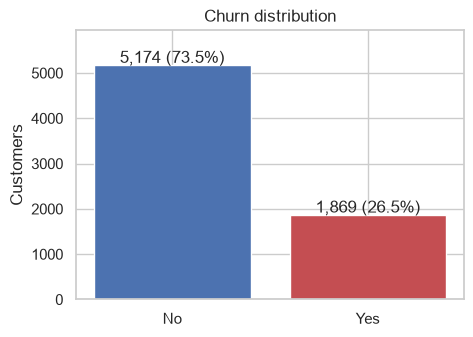

In [7]:
churn_rate = df["Churn_flag"].mean()
print(f"Churn rate: {churn_rate:.1%}  ({df['Churn_flag'].sum():,} of {len(df):,} customers)")

fig, ax = plt.subplots(figsize=(5, 3.5))
counts = df["Churn"].value_counts()
ax.bar(counts.index, counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 50, f"{v:,} ({v/len(df):.1%})", ha="center")
ax.set_title("Churn distribution")
ax.set_ylabel("Customers")
ax.set_ylim(0, counts.max() * 1.15)
save(fig, "01_churn_distribution.png")
plt.show()

About **1 in 4** customers churn: the classes are **imbalanced**. A model that always predicts
"No churn" would already be ~73% accurate while catching zero churners — that is why we will judge
models with ROC-AUC, PR-AUC, precision and recall, not accuracy.

## 5. Numeric distributions by churn

       tenure  MonthlyCharges  TotalCharges
count  7043.0          7043.0        7043.0
mean     32.4            64.8        2279.7
std      24.6            30.1        2266.8
min       0.0            18.2           0.0
25%       9.0            35.5         398.6
50%      29.0            70.4        1394.6
75%      55.0            89.8        3786.6
max      72.0           118.8        8684.8


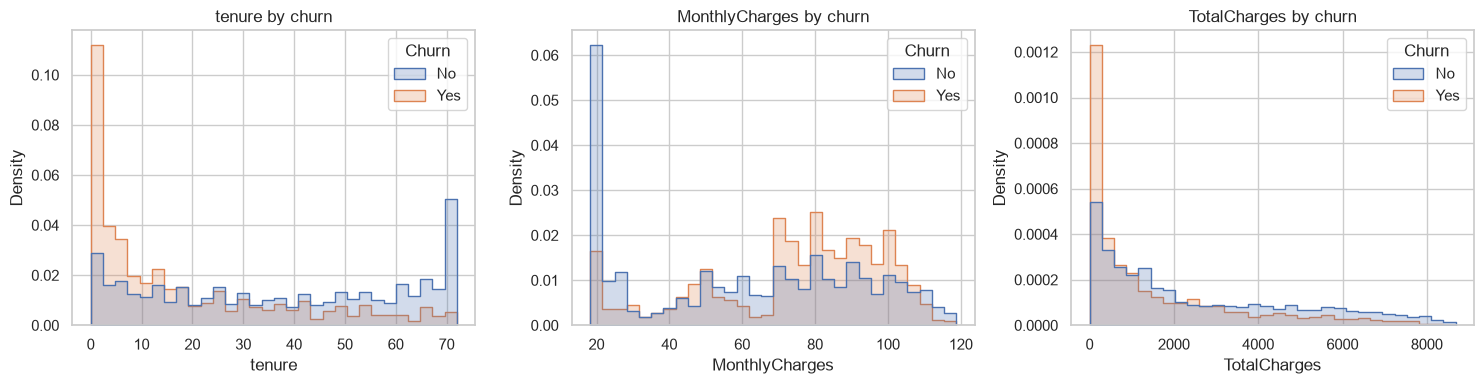

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,38.0,64.4,1679.5
Yes,10.0,79.6,703.6


In [8]:
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
print(df[num_cols].describe().round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, stat="density", common_norm=False,
                 element="step", ax=ax)
    ax.set_title(f"{col} by churn")
fig.tight_layout()
save(fig, "02_numeric_distributions.png")
plt.show()

df.groupby("Churn")[num_cols].median().round(1)

## 6. Churn rate by key business segments

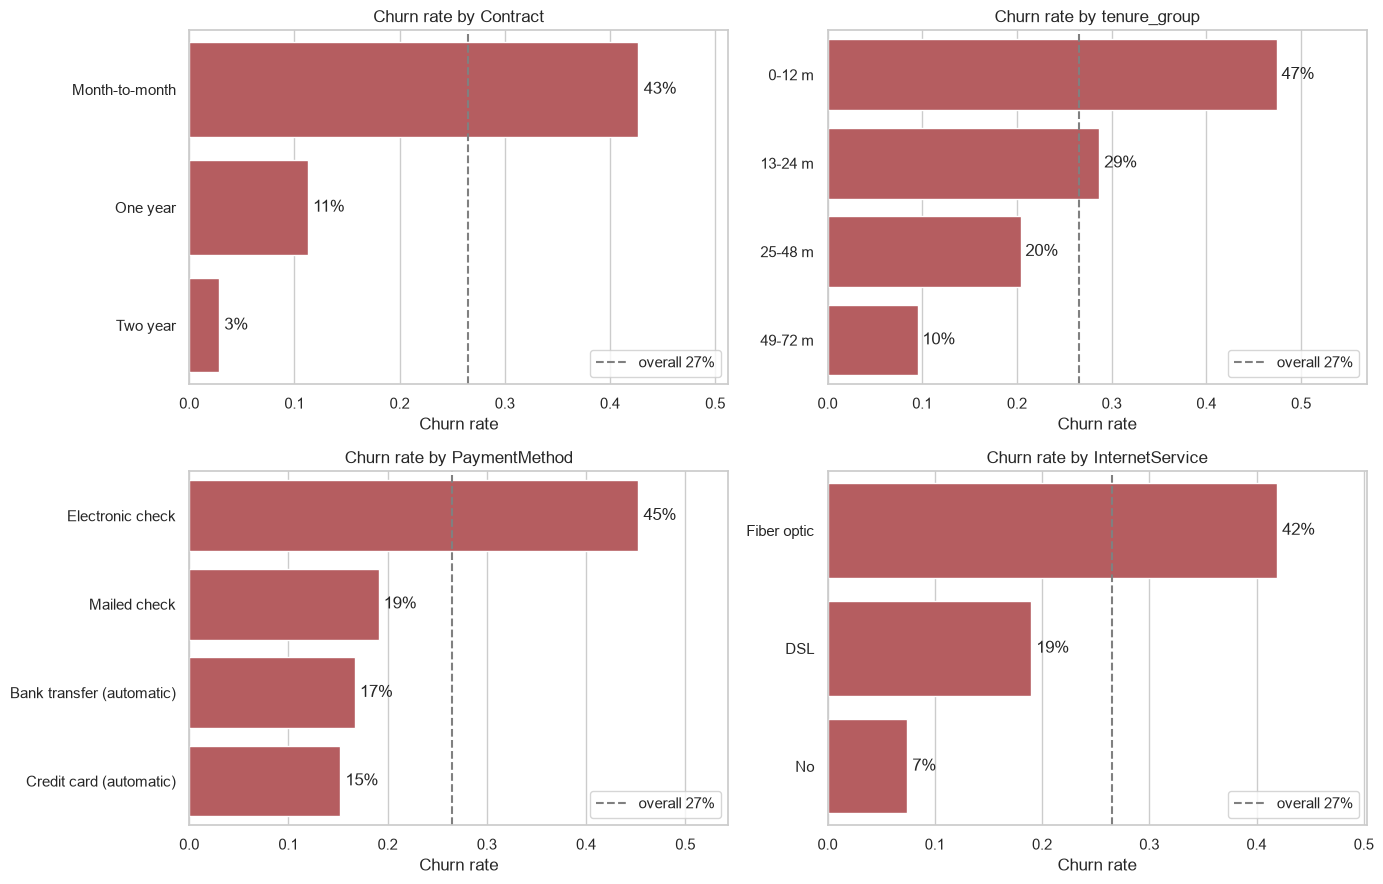

In [9]:
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 m", "13-24 m", "25-48 m", "49-72 m"])

segments = ["Contract", "tenure_group", "PaymentMethod", "InternetService"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), segments):
    rates = df.groupby(col, observed=True)["Churn_flag"].mean().sort_values(ascending=False)
    sns.barplot(x=rates.values, y=rates.index.astype(str), ax=ax, color="#C44E52")
    ax.axvline(churn_rate, ls="--", c="grey", label=f"overall {churn_rate:.0%}")
    for i, v in enumerate(rates.values):
        ax.text(v + 0.005, i, f"{v:.0%}", va="center")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate")
    ax.set_ylabel("")
    ax.set_xlim(0, max(rates.max() * 1.2, 0.5))
    ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "03_churn_rate_by_segment.png")
plt.show()

In [10]:
for col in segments:
    t = df.groupby(col, observed=True)["Churn_flag"].agg(customers="size", churn_rate="mean")
    print(t.assign(churn_rate=lambda x: (x.churn_rate * 100).round(1)).to_string(), "\n")

                customers  churn_rate
Contract                             
Month-to-month       3875        42.7
One year             1473        11.3
Two year             1695         2.8 

              customers  churn_rate
tenure_group                       
0-12 m             2186        47.4
13-24 m            1024        28.7
25-48 m            1594        20.4
49-72 m            2239         9.5 

                           customers  churn_rate
PaymentMethod                                   
Bank transfer (automatic)       1544        16.7
Credit card (automatic)         1522        15.2
Electronic check                2365        45.3
Mailed check                    1612        19.1 

                 customers  churn_rate
InternetService                       
DSL                   2421        19.0
Fiber optic           3096        41.9
No                    1526         7.4 



## 7. Churn rate for the remaining categorical features

In [11]:
other_cats = ["SeniorCitizen", "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
              "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
              "StreamingTV", "StreamingMovies", "PaperlessBilling"]
rows = []
for col in other_cats:
    for level, g in df.groupby(col):
        rows.append({"feature": col, "level": level, "customers": len(g),
                     "churn_rate_%": round(g["Churn_flag"].mean() * 100, 1)})
cat_table = pd.DataFrame(rows)
cat_table.pivot_table(index="feature", columns="level", values="churn_rate_%")

level,0,1,Female,Male,No,No internet service,No phone service,Yes
feature,,,,,,,,
Dependents,NaN,NaN,NaN,NaN,31.3,NaN,NaN,15.5
DeviceProtection,NaN,NaN,NaN,NaN,39.1,7.4,NaN,22.5
MultipleLines,NaN,NaN,NaN,NaN,25.0,NaN,24.9,28.6
OnlineBackup,NaN,NaN,NaN,NaN,39.9,7.4,NaN,21.5
OnlineSecurity,NaN,NaN,NaN,NaN,41.8,7.4,NaN,14.6
PaperlessBilling,NaN,NaN,NaN,NaN,16.3,NaN,NaN,33.6
Partner,NaN,NaN,NaN,NaN,33.0,NaN,NaN,19.7
PhoneService,NaN,NaN,NaN,NaN,24.9,NaN,NaN,26.7
SeniorCitizen,23.6,41.7,NaN,NaN,NaN,NaN,NaN,NaN


## 8. Correlations

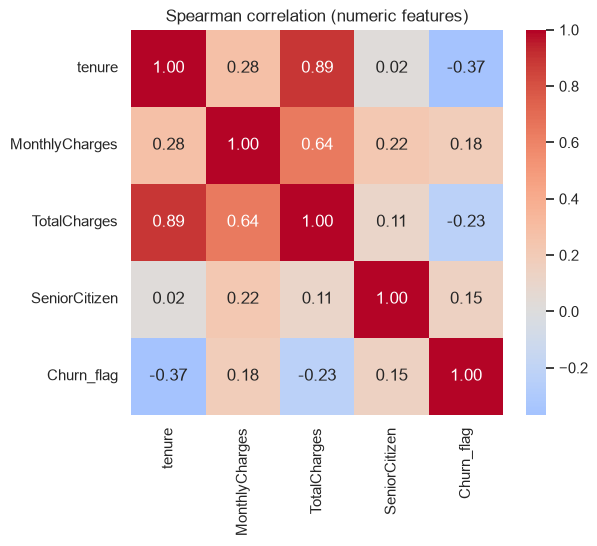

In [12]:
# Numeric correlations (Spearman: robust to skew and non-linear but monotonic relations)
corr = df[num_cols + ["SeniorCitizen", "Churn_flag"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Spearman correlation (numeric features)")
save(fig, "04_correlation_heatmap.png")
plt.show()

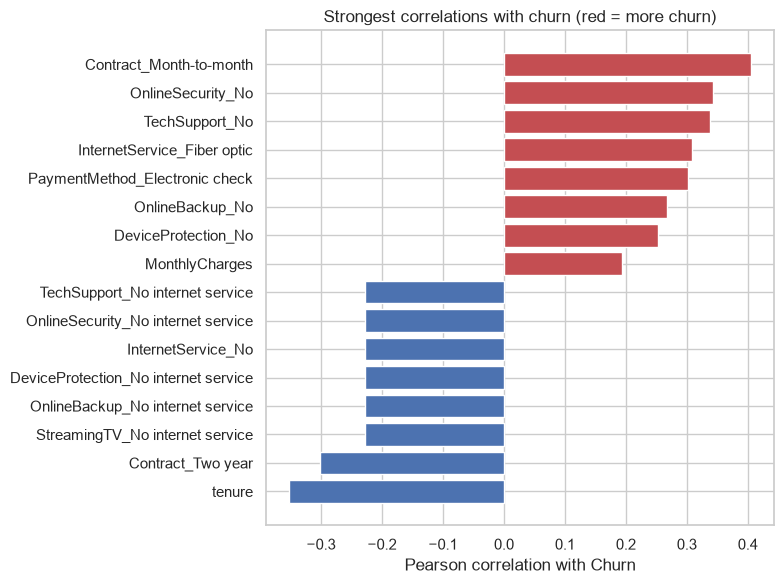

tenure                                 -0.352
Contract_Two year                      -0.302
StreamingTV_No internet service        -0.228
OnlineBackup_No internet service       -0.228
DeviceProtection_No internet service   -0.228
InternetService_No                     -0.228
OnlineSecurity_No internet service     -0.228
TechSupport_No internet service        -0.228
MonthlyCharges                          0.193
DeviceProtection_No                     0.252
OnlineBackup_No                         0.268
PaymentMethod_Electronic check          0.302
InternetService_Fiber optic             0.308
TechSupport_No                          0.337
OnlineSecurity_No                       0.343
Contract_Month-to-month                 0.405
dtype: float64

In [13]:
# Correlation of every one-hot encoded category with churn: a quick ranking of signals
dummies = pd.get_dummies(df.drop(columns=["customerID", "Churn", "Churn_flag", "tenure_group"]),
                         dtype=float)
churn_corr = dummies.corrwith(df["Churn_flag"]).sort_values()
top = pd.concat([churn_corr.head(8), churn_corr.tail(8)])

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=["#4C72B0" if v < 0 else "#C44E52" for v in top.values])
ax.set_title("Strongest correlations with churn (red = more churn)")
ax.set_xlabel("Pearson correlation with Churn")
fig.tight_layout()
save(fig, "05_churn_correlations.png")
plt.show()
top.round(3)

In [14]:
# tenure and TotalCharges are strongly related (TotalCharges ~ tenure x MonthlyCharges)
print(f"corr(tenure, TotalCharges) = {df['tenure'].corr(df['TotalCharges']):.2f}")

corr(tenure, TotalCharges) = 0.83


## Key insights

1. **Churn is a minority class (26.5%, 1,869 of 7,043 customers).** Accuracy would be misleading — a model that never predicts churn is already 73.5% "accurate". We will use ROC-AUC, PR-AUC, precision and recall.
2. **Contract type is the strongest signal.** Month-to-month customers churn at **42.7%**, versus **11.3%** on one-year and only **2.8%** on two-year contracts. Moving customers to longer contracts is the most obvious retention lever.
3. **The first year is the danger zone.** Customers in their first 12 months churn at **47.4%**; after 4 years it drops to **9.5%**. Churners have a median tenure of 10 months vs 38 for those who stay — onboarding matters.
4. **Fiber optic customers churn far more (41.9%)** than DSL (19.0%) or customers without internet (7.4%), and churners pay more per month (median $79.6 vs $64.4). This hints at a price/quality problem with the fiber offer.
5. **Electronic check payers churn at 45.3%**, roughly 3x more than customers on automatic bank transfer (16.7%) or credit card (15.2%). Pushing auto-pay is a cheap retention action.
6. **Support/security add-ons go with loyalty.** Without OnlineSecurity or TechSupport, churn is ~42%; with them it is ~15%. Senior citizens (41.7%) and customers without a partner or dependents also churn more. Gender has no effect (26.9% vs 26.2%).
7. **Data quality:** 11 blank `TotalCharges` values, all for tenure = 0 customers (not yet billed) → set to 0. No duplicated customer IDs. `tenure` and `TotalCharges` are highly correlated (0.83), which matters for interpreting linear models.